# Imports

In [1]:
import pandas as pd
import mlflow
import os
import numpy as np
import seaborn as sns

In [27]:
import json
from pathlib import Path

In [41]:
import matplotlib.pyplot as plt
import math

# Config

In [2]:
os.environ["MLFLOW_TRACKING_URI"]="sqlite:///mlflow.db"

# Data

In [3]:
client = mlflow.tracking.MlflowClient(tracking_uri="sqlite:///mlflow.db", registry_uri="sqlite:///mlflow.db")

2025/11/28 15:29:29 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2025/11/28 15:29:29 INFO mlflow.store.db.utils: Updating database tables
2025-11-28 15:29:29 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
2025-11-28 15:29:29 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
2025-11-28 15:29:29 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
2025-11-28 15:29:29 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


In [4]:
client.search_experiments()

[<Experiment: artifact_location='file:C:/Users/alast/dev/uni-dev/mat502-ai/mat501-coursework-project/mlruns/2', creation_time=1764247621029, experiment_id='2', last_update_time=1764247621029, lifecycle_stage='active', name='snake-small-test', tags={'mlflow.experimentKind': 'custom_model_development'}>,
 <Experiment: artifact_location='file:C:/Users/alast/dev/uni-dev/mat502-ai/mat501-coursework-project/mlruns/1', creation_time=1764183510934, experiment_id='1', last_update_time=1764183510934, lifecycle_stage='active', name='snake', tags={'mlflow.experimentKind': 'custom_model_development'}>,
 <Experiment: artifact_location='file:C:/Users/alast/dev/uni-dev/mat502-ai/mat501-coursework-project/mlruns/0', creation_time=1764183510925, experiment_id='0', last_update_time=1764183510925, lifecycle_stage='active', name='Default', tags={}>]

In [81]:
experiment=client.get_experiment_by_name("snake")

In [82]:
runs = client.search_runs([experiment.experiment_id])

In [83]:
run_df = pd.DataFrame([run.data.params | run.data.metrics for run in runs])

In [84]:
param_cols = list(runs[-1].data.params.keys())

In [31]:
plot_df = run_df[run_df["Average End Snake Length"] > 20][["Average End Snake Length"]+param_cols].astype(float)

In [32]:
plot_df.head()

,Average End Snake Length,max_depth,min_child_weight,gamma,subsample,colsample_bytree,colsample_bylevel,colsample_bynode,eta,lambda,alpha,max_delta_step,n_estimators,scale_pos_weight
150,22.5,5.0,11.0,8.209768,0.585419,0.685340,0.935517,0.604674,0.014354,0.004219,0.441762,6.0,1871.0,3.689859
151,23.0,9.0,19.0,1.003221,0.557616,0.532196,0.798348,0.851520,0.008975,1.933718,0.000173,9.0,1467.0,8.981078
152,21.0,12.0,7.0,4.702136,0.811291,0.719743,0.725076,0.664452,0.089135,0.065126,0.002771,7.0,769.0,6.678883
154,21.0,5.0,18.0,0.365799,0.609594,0.726906,0.683322,0.804645,0.105830,3.720727,6.151571,8.0,795.0,0.914925
157,25.5,6.0,8.0,9.633432,0.950579,0.615723,0.992256,0.746439,0.103775,0.014398,1.013652,5.0,620.0,1.695707


# Simulation Data Analysis

In [4]:
run = client.get_run("03325264f148448ab7fd1850fa5e33f2")

In [18]:
client.download_artifacts(run_id="03325264f148448ab7fd1850fa5e33f2", path="simulated_results.json", dst_path="./.data/")

'C:\\Users\\alast\\dev\\uni-dev\\mat502-ai\\mat501-coursework-project\\.data\\simulated_results.json'

In [30]:
data_dict = json.load(Path("./.data/simulated_results.json").open("r"))

In [85]:
df = pd.DataFrame(data_dict["data"], columns=data_dict["columns"])

<Axes: xlabel='input_RIGHT', ylabel='count'>

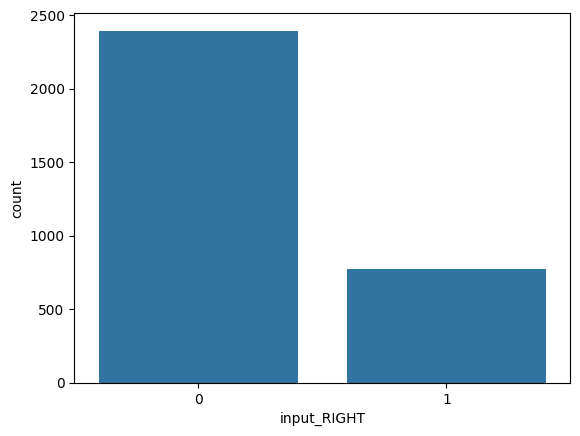

In [50]:
sns.countplot(x=df["input_RIGHT"])

In [62]:
# Copilot code
# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(exclude=['number']).columns

all_cols = list(df.columns)

for i, col in enumerate(all_cols):
    plt.figure(figsize=(6, 4))
    
    if col in numeric_cols:
        # Histogram for numeric columns
        sns.histplot(df[col], kde=False)
        plt.xlabel(col)
        plt.ylabel("Count")
        
        # Calculate skew and kurtosis if float
        if pd.api.types.is_float_dtype(df[col]):
            skew = df[col].skew()
            kurt = df[col].kurtosis()
            plt.title(f"Histogram of {col}\nSkew: {skew:.2f}, Kurtosis: {kurt:.2f}")
        else:
            plt.title(f"Categorical Counts of {col}")
            plt.xticks([0, 1], ['0', '1'])
            
    
    else:
        # Bar chart for categorical columns
        sns.countplot(x=df[col])
        plt.title(f"Bar Chart of {col}")


    filepath = f".data/figures/{col}_plot.png"
    plt.tight_layout()
    plt.savefig(filepath)
    plt.close()

    print(f"Saved plot for '{col}' as {filepath}")

Saved plot for 'normalised_distance_to_wall_x' as .data/figures/normalised_distance_to_wall_x_plot.png
Saved plot for 'normalised_distance_to_wall_y' as .data/figures/normalised_distance_to_wall_y_plot.png
Saved plot for 'normalised_fruit_position_x_delta' as .data/figures/normalised_fruit_position_x_delta_plot.png
Saved plot for 'normalised_fruit_position_y_delta' as .data/figures/normalised_fruit_position_y_delta_plot.png
Saved plot for 'closest_segment_x_delta' as .data/figures/closest_segment_x_delta_plot.png
Saved plot for 'closest_segment_y_delta' as .data/figures/closest_segment_y_delta_plot.png
Saved plot for 'input_UP' as .data/figures/input_UP_plot.png
Saved plot for 'input_DOWN' as .data/figures/input_DOWN_plot.png
Saved plot for 'input_LEFT' as .data/figures/input_LEFT_plot.png
Saved plot for 'input_RIGHT' as .data/figures/input_RIGHT_plot.png
Saved plot for 'current_UP' as .data/figures/current_UP_plot.png
Saved plot for 'current_DOWN' as .data/figures/current_DOWN_plot.pn

# Model Performance

In [70]:
random_forest_experiment = client.get_experiment_by_name("snake-random-forest-only")

In [72]:
runs = client.search_runs([random_forest_experiment.experiment_id]) 

In [75]:
pd.DataFrame([run.data.metrics for run in runs]).dropna().to_csv(".data/

,R2_avg,R2_std,R2_valid,RMSE_avg,RMSE_std,RMSE_valid,MAE_avg,MAE_std,MAE_valid,model_from_random_simulation_train_time_s,...,Average Run Length,Std Run Length,Max Run Length,Median End Snake Length,Average End Snake Length,Std End Snake Length,Max End Snake Length,Average Model Inference Time,Std Model Inference Time,Max Model Inference Time
4,0.604,0.019,0.618,0.329,0.008,0.324,0.237,0.001,0.237,3.628,...,306.7,453.217,999.0,1.0,1.0,0.0,1.0,0.116,0.051,0.373
5,0.998,0.000,0.999,0.024,0.002,0.019,0.001,0.000,0.001,3.132,...,393.0,343.953,999.0,31.5,31.5,30.5,62.0,0.026,0.011,0.077
6,0.998,0.000,0.998,0.024,0.002,0.021,0.001,0.000,0.001,13.489,...,205.8,287.913,999.0,22.5,22.5,21.5,44.0,0.120,0.047,0.337
7,0.998,0.000,0.998,0.024,0.001,0.025,0.001,0.000,0.002,10.758,...,316.0,373.349,999.0,27.0,27.0,26.0,53.0,0.074,0.029,0.194
9,0.998,0.000,0.999,0.020,0.002,0.020,0.001,0.000,0.001,7.862,...,735.5,403.240,999.0,15.0,15.0,14.0,29.0,0.108,0.043,0.315
10,0.578,0.024,0.562,0.340,0.010,0.346,0.236,0.002,0.238,2.848,...,603.4,484.509,999.0,1.0,1.0,0.0,1.0,0.056,0.024,0.212
11,0.928,0.012,0.919,0.140,0.012,0.149,0.074,0.006,0.079,5.915,...,113.9,160.685,492.0,22.5,22.5,21.5,44.0,0.060,0.021,0.214
12,0.726,0.003,0.730,0.274,0.002,0.273,0.184,0.002,0.185,4.541,...,504.5,494.500,999.0,1.0,1.0,0.0,1.0,0.101,0.045,0.294
14,0.998,0.000,0.998,0.022,0.002,0.023,0.001,0.000,0.001,9.529,...,718.0,344.443,999.0,22.5,22.5,21.5,44.0,0.116,0.051,0.338
16,0.997,0.001,0.998,0.027,0.003,0.022,0.002,0.000,0.001,12.073,...,485.0,390.003,999.0,33.0,33.0,32.0,65.0,0.123,0.046,0.291


In [76]:
import xgboost

In [77]:
import mlflow.xgboost

In [78]:
mdl = mlflow.xgboost.load_model("runs:/03325264f148448ab7fd1850fa5e33f2/model")

<Axes: title={'center': 'Feature Importances'}, xlabel='Importance', ylabel='Feature'>

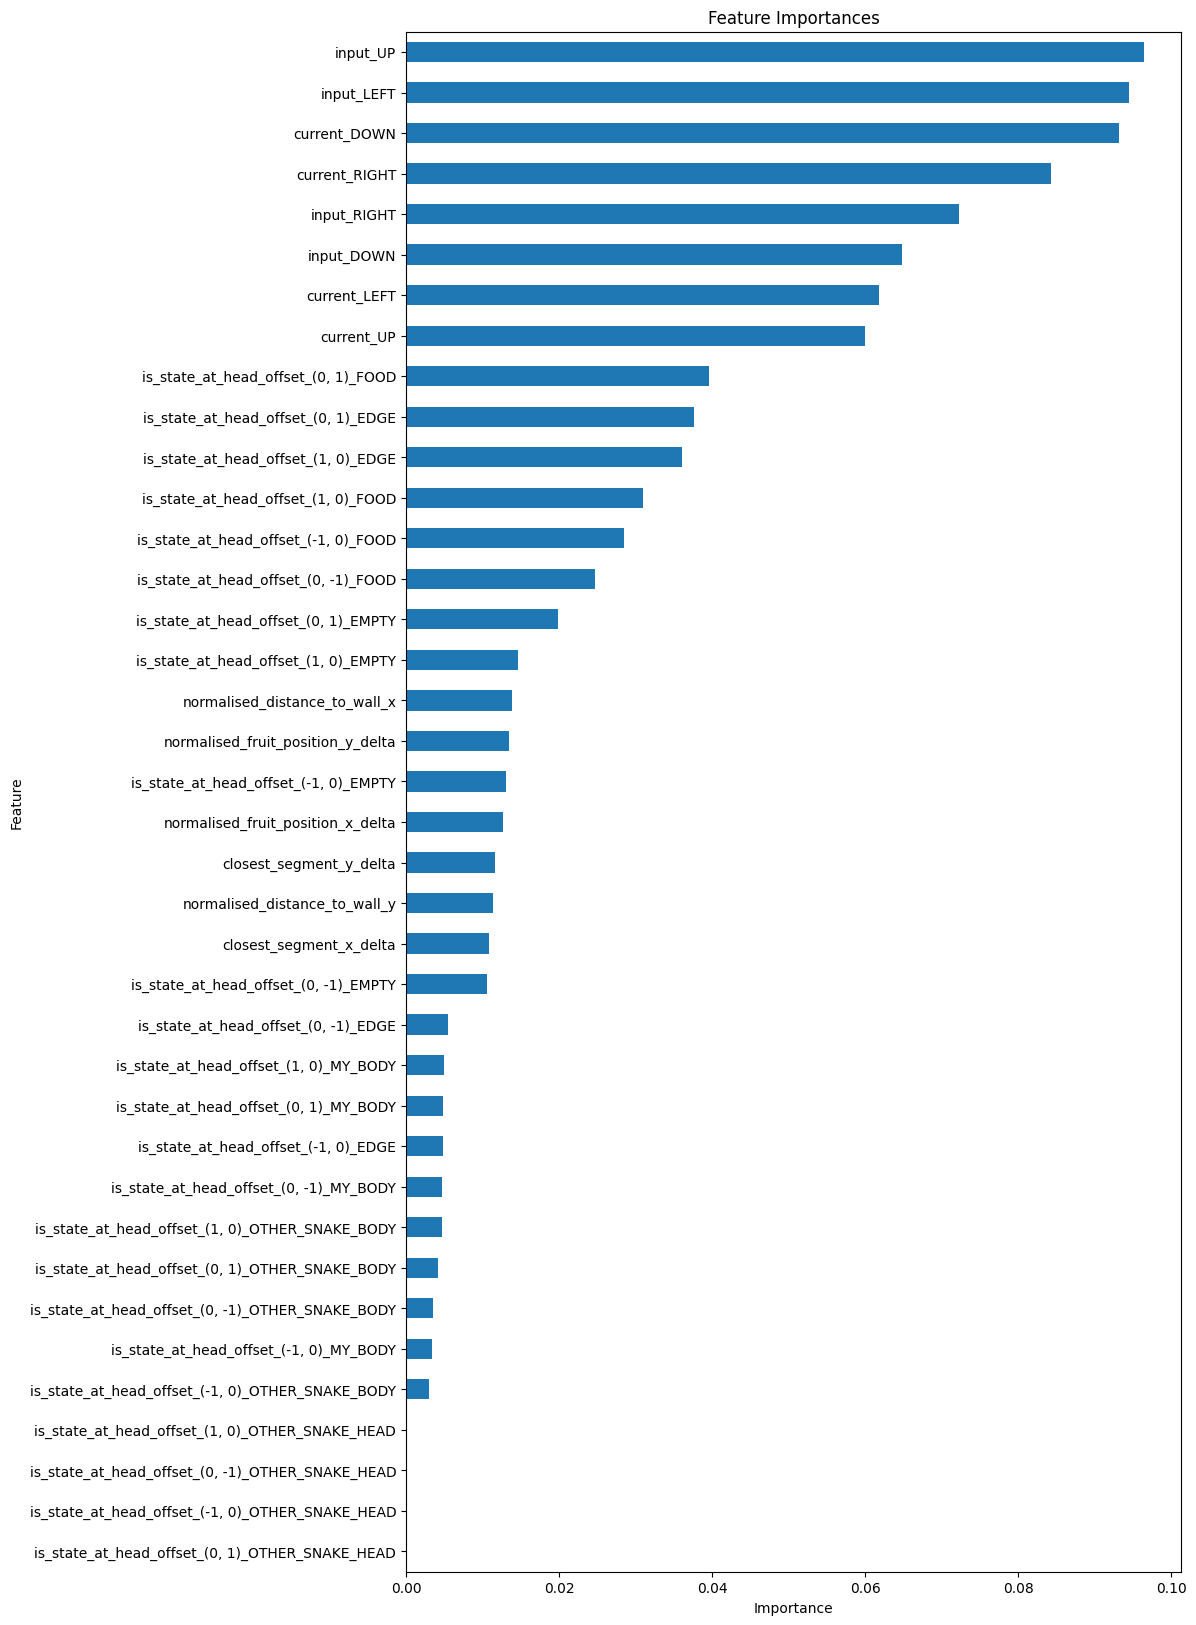

In [88]:
mdl = mlflow.xgboost.load_model("runs:/03325264f148448ab7fd1850fa5e33f2/model")
feature_importances = pd.Series(
    mdl.feature_importances_,
    index=df.drop("reward", axis=1).columns,
).sort_values(ascending=True)
feature_importances.plot(
    kind="barh",
    title="Feature Importances",
    xlabel="Importance",
    ylabel="Feature",
    figsize=(10, 20),
)


<Axes: title={'center': 'Feature Importances'}, xlabel='Importance', ylabel='Feature'>

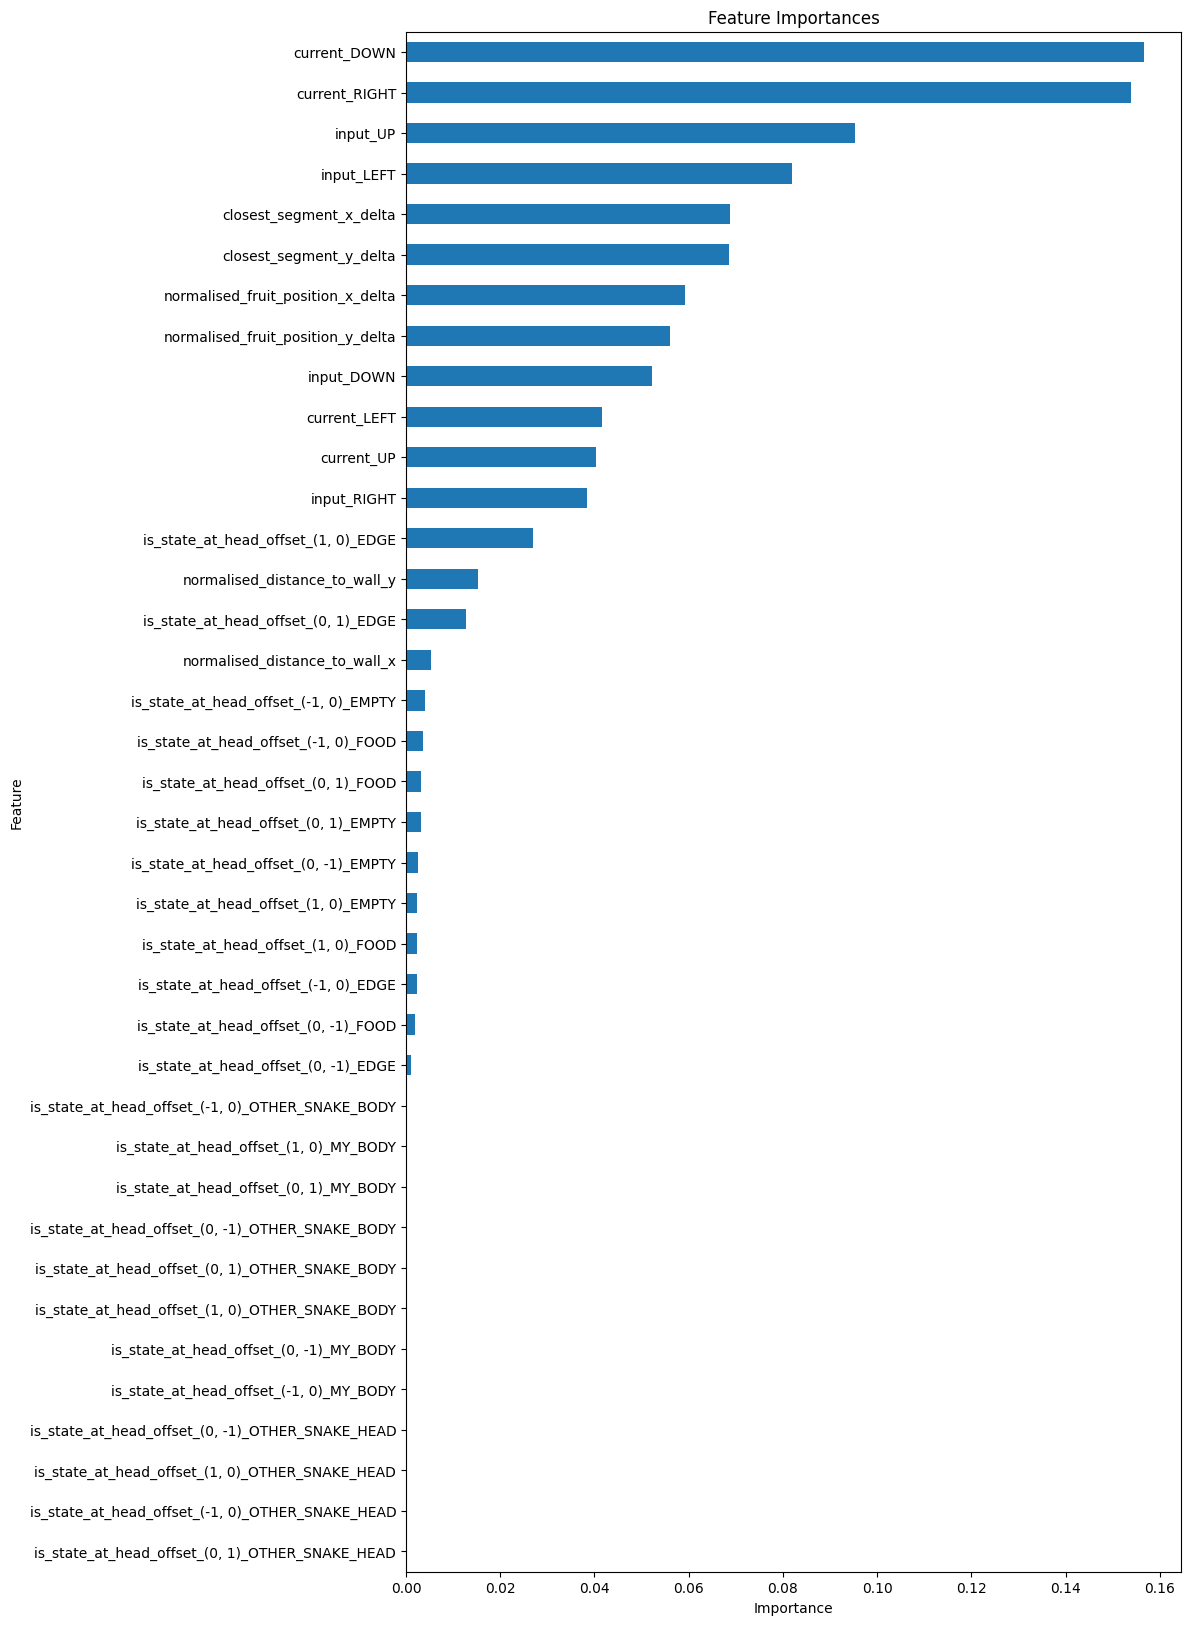

In [89]:
mdl = mlflow.sklearn.load_model("runs:/690df87c73f64f4cbf94578715771c7a/model")
feature_importances = pd.Series(
    mdl.feature_importances_,
    index=df.drop("reward", axis=1).columns,
).sort_values(ascending=True)
feature_importances.plot(
    kind="barh",
    title="Feature Importances",
    xlabel="Importance",
    ylabel="Feature",
    figsize=(10, 20),
)
